# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from transformers import BertModel, BertTokenizer

In [2]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
bert = BertModel.from_pretrained('bert-base-uncased').to(device)
bert

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=False)
  

# Load Dataset

In [3]:
!pip install -U datasets huggingface_hub fsspec

  Using cached huggingface_hub-2.0.0-py3-none-any.whl.metadata (16 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)


In [4]:
from datasets import load_dataset

dataset = load_dataset("stanfordnlp/imdb")
dataset

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

# Model

In [5]:
text = 'Replace me with any text you like.'
tokens = tokenizer(text, return_tensors='pt').to(device)
tokens

{'input_ids': tensor([[ 101, 5672, 2033, 2007, 2151, 3793, 2017, 2066, 1012,  102]],
       device='cuda:0'), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], device='cuda:0'), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]], device='cuda:0')}

In [6]:
# $ get model output using specific inputs
output = bert(
    input_ids      = tokens['input_ids'],
    attention_mask = tokens['attention_mask']
)

output = bert(**tokens)
output

BaseModelOutputWithPoolingAndCrossAttentions(last_hidden_state=tensor([[[ 0.0965,  0.1224, -0.1108,  ..., -0.3743, -0.2982,  0.4477],
         [ 0.1753, -0.3893,  0.0588,  ...,  0.4928,  0.2224, -0.0216],
         [ 0.1914, -0.5786,  0.2360,  ..., -0.4829,  0.2683,  0.8821],
         ...,
         [ 0.4420,  0.3172,  1.0196,  ..., -0.8215, -0.6848, -0.2039],
         [-0.1163, -0.7017, -0.5098,  ...,  0.1276, -0.6230, -0.5058],
         [ 0.8552,  0.1882, -0.1018,  ...,  0.0646, -0.5835, -0.1768]]],
       device='cuda:0', grad_fn=<NativeLayerNormBackward0>), pooler_output=tensor([[-0.9218, -0.4858, -0.9734,  0.8850,  0.9313, -0.2544,  0.8515,  0.2431,
         -0.9497, -1.0000, -0.8874,  0.9859,  0.9832,  0.6912,  0.9291, -0.8323,
         -0.5453, -0.6562,  0.3008, -0.1131,  0.7066,  1.0000, -0.4118,  0.3926,
          0.6177,  0.9995, -0.8656,  0.9496,  0.9522,  0.6979, -0.6519,  0.3295,
         -0.9945, -0.2477, -0.9612, -0.9935,  0.6465, -0.7298,  0.0884,  0.0989,
         -0.944

In [7]:
class BertForBinaryClassification(nn.Module):
  def __init__(self, num_labels=2):
    super().__init__()

    # Load the pretrained BERT model
    self.bert = BertModel.from_pretrained('bert-base-uncased')

    # classification head that converts the 768-d pooled output into 2 final outputs
    self.classifier = nn.Linear(768,2)
    self.dropout    = nn.Dropout(self.bert.embeddings.dropout.p) # 10%

    # initialize the weights and biases
    nn.init.xavier_uniform_(self.classifier.weight)
    nn.init.zeros_(self.classifier.bias)

  def forward(self, input_ids, attention_mask=None, token_type_ids=None):

    # forward pass through the downloaded (pretrained) BERT
    outputs = self.bert(
        input_ids = input_ids,
        attention_mask = attention_mask,
        token_type_ids = token_type_ids
    )

    # extract the pooled output and apply dropout
    pooled_output = self.dropout(outputs.pooler_output)

    # final push through the classification layer
    logits = self.classifier(pooled_output)

    return logits

In [8]:
# create an instance of the model and test it
model = BertForBinaryClassification().to(device)

# test the output
tokens = tokenizer(text, return_tensors='pt').to(device)
out = model(**tokens)
out

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tensor([[-0.4385,  2.1843]], device='cuda:0', grad_fn=<AddmmBackward0>)

# Data

In [9]:
from datasets import DatasetDict

small_data = DatasetDict({
    split: dataset[split].select(range(0, 15000)) for split in ['train', 'test']
})
small_data

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 15000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 15000
    })
})

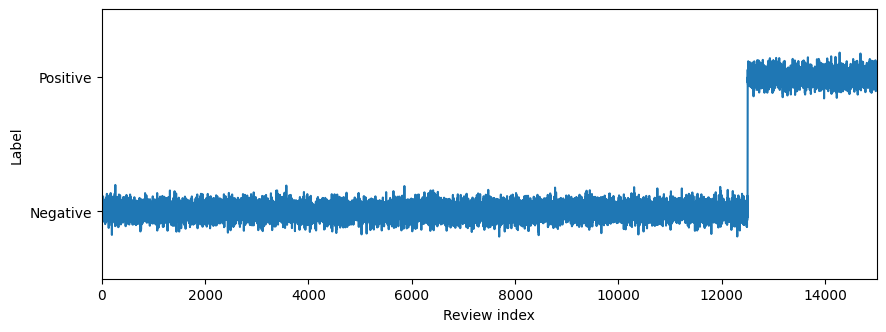

In [10]:
# confirm we still have both categories
plt.figure(figsize=(10, 3.5))

plt.plot(
    small_data['train']['label']
    + np.random.randn(len(small_data['train'])) / 20
)

plt.gca().set(
    xlabel='Review index',
    ylabel='Label',
    yticks=[0, 1],
    yticklabels=['Negative', 'Positive'],
    xlim=[0, len(small_data['train'])],
    ylim=[-.5, 1.5]
)

plt.show()

# Tokenizing text with padding

In [11]:
first_try = tokenizer(dataset['train'][0]['text'])

# but this is better b/c reviews have differing lenghts
better = tokenizer(
    dataset['train'][0]['text'], # the text to tokenize
    max_length = 512,
    padding    = 'max_length', # using pad_token to reach max_len
    truncation = True
)

print(f'Naive\' tokenization (N = {len(first_try["input_ids"])})')
print(f'{first_try['input_ids']}')

print(f"\nBetter tokenization (N={len(better['input_ids'])}):")
print(f"{better['input_ids']}")

Naive' tokenization (N = 363)
[101, 1045, 12524, 1045, 2572, 8025, 1011, 3756, 2013, 2026, 2678, 3573, 2138, 1997, 2035, 1996, 6704, 2008, 5129, 2009, 2043, 2009, 2001, 2034, 2207, 1999, 3476, 1012, 1045, 2036, 2657, 2008, 2012, 2034, 2009, 2001, 8243, 2011, 1057, 1012, 1055, 1012, 8205, 2065, 2009, 2412, 2699, 2000, 4607, 2023, 2406, 1010, 3568, 2108, 1037, 5470, 1997, 3152, 2641, 1000, 6801, 1000, 1045, 2428, 2018, 2000, 2156, 2023, 2005, 2870, 1012, 1026, 7987, 1013, 1028, 1026, 7987, 1013, 1028, 1996, 5436, 2003, 8857, 2105, 1037, 2402, 4467, 3689, 3076, 2315, 14229, 2040, 4122, 2000, 4553, 2673, 2016, 2064, 2055, 2166, 1012, 1999, 3327, 2016, 4122, 2000, 3579, 2014, 3086, 2015, 2000, 2437, 2070, 4066, 1997, 4516, 2006, 2054, 1996, 2779, 25430, 14728, 2245, 2055, 3056, 2576, 3314, 2107, 2004, 1996, 5148, 2162, 1998, 2679, 3314, 1999, 1996, 2142, 2163, 1012, 1999, 2090, 4851, 8801, 1998, 6623, 7939, 4697, 3619, 1997, 8947, 2055, 2037, 10740, 2006, 4331, 1010, 2016, 2038, 3348, 2007,

In [12]:
def tokenize_function(one_sample):
  return tokenizer(
      one_sample['text'],
      max_length = 512,
      padding = 'max_length',
      truncation = True # truncate sequences longer than max_length
  )

# apply tokenization func
tokenized_dataset = small_data.map(tokenize_function, batched = True)
tokenized_dataset

Map:   0%|          | 0/15000 [00:00<?, ? examples/s]

Map:   0%|          | 0/15000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 15000
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 15000
    })
})

# DataLoaders

In [13]:
# remove text pair
tokenized_dataset = tokenized_dataset.remove_columns(['text'])

# change format to pytorch tensors
tokenized_dataset.set_format('torch', columns = ['input_ids', 'attention_mask', 'label'])

# create DataLoaders for training and testing
train_dataloader = DataLoader(tokenized_dataset['train'], shuffle=True, batch_size = 32)
test_dataloader  = DataLoader(tokenized_dataset['test'], batch_size = 32)

In [14]:
X = next(iter(train_dataloader))
X

{'label': tensor([1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 1, 0]),
 'input_ids': tensor([[ 101, 2043, 1045,  ...,    0,    0,    0],
         [ 101, 3466, 1006,  ...,    0,    0,    0],
         [ 101, 1996, 3772,  ...,    0,    0,    0],
         ...,
         [ 101, 2023, 2143,  ...,    0,    0,    0],
         [ 101, 1996, 2466,  ...,    0,    0,    0],
         [ 101, 1045, 2074,  ...,    0,    0,    0]]),
 'attention_mask': tensor([[1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0],
         ...,
         [1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0]])}

# Fine-Tune

In [15]:
# optimizer and loss
optimizer = torch.optim.AdamW(model.parameters(), lr = 1e-5)
loss_fn = nn.CrossEntropyLoss() # ce loss for multi-class classification

In [ ]:
import numpy as np

num_batches = 300
log_every = 10
num_logs = num_batches // log_every

train_losses   = np.zeros(num_logs)
train_accuracy = np.zeros(num_logs)
test_losses    = np.zeros(num_logs)
test_accuracy  = np.zeros(num_logs)

running_loss = 0
running_acc = 0
log_idx = 0

model.train()

for i, batch in enumerate(train_dataloader):

    if i >= num_batches:
        break

    tokenz  = batch['input_ids'].to(device)
    att_msk = batch['attention_mask'].to(device)
    labels  = batch['label'].to(device)

    optimizer.zero_grad()

    logits = model(tokenz, attention_mask=att_msk)
    loss = loss_fn(logits, labels)

    pred_labels = torch.argmax(logits, dim=1)
    acc = (pred_labels == labels).float().mean()

    loss.backward()
    optimizer.step()

    running_loss += loss.item()
    running_acc += acc.item()

    if (i + 1) % log_every == 0:

        # TRAIN metrics
        train_losses[log_idx] = running_loss / log_every
        train_accuracy[log_idx] = running_acc / log_every

        # TEST metrics
        model.eval()

        test_loss = 0
        test_acc = 0

        with torch.no_grad():

            for test_batch in test_dataloader:

                tokenz_test  = test_batch['input_ids'].to(device)
                att_msk_test = test_batch['attention_mask'].to(device)
                labels_test  = test_batch['label'].to(device)

                logits_test = model(tokenz_test, attention_mask=att_msk_test)
                loss_test = loss_fn(logits_test, labels_test)

                pred_test = torch.argmax(logits_test, dim=1)
                acc_test = (pred_test == labels_test).float().mean()

                test_loss += loss_test.item()
                test_acc += acc_test.item()

        test_losses[log_idx] = test_loss / len(test_dataloader)
        test_accuracy[log_idx] = test_acc / len(test_dataloader)

        print(
            f"Batch {i+1}/{num_batches} | "
            f"Train loss: {train_losses[log_idx]:.4f} | "
            f"Test loss: {test_losses[log_idx]:.4f} | "
            f"Train acc: {train_accuracy[log_idx]:.4f} | "
            f"Test acc: {test_accuracy[log_idx]:.4f}"
        )

        running_loss = 0
        running_acc = 0
        log_idx += 1

        model.train()

Batch 10/300 | Train loss: 0.6818 | Test loss: 0.4526 | Train acc: 0.6750 | Test acc: 0.8329
Batch 20/300 | Train loss: 0.3994 | Test loss: 0.4426 | Train acc: 0.8656 | Test acc: 0.8329
Batch 30/300 | Train loss: 0.4797 | Test loss: 0.4391 | Train acc: 0.8219 | Test acc: 0.8329
Batch 40/300 | Train loss: 0.4388 | Test loss: 0.4297 | Train acc: 0.8500 | Test acc: 0.8329
Batch 50/300 | Train loss: 0.3696 | Test loss: 0.4436 | Train acc: 0.8750 | Test acc: 0.8329
Batch 60/300 | Train loss: 0.4681 | Test loss: 0.4083 | Train acc: 0.8250 | Test acc: 0.8329
Batch 70/300 | Train loss: 0.4486 | Test loss: 0.3916 | Train acc: 0.8094 | Test acc: 0.8330
Batch 80/300 | Train loss: 0.4130 | Test loss: 0.3552 | Train acc: 0.8313 | Test acc: 0.8332
Batch 90/300 | Train loss: 0.3240 | Test loss: 0.2734 | Train acc: 0.8531 | Test acc: 0.8861
Batch 100/300 | Train loss: 0.2586 | Test loss: 0.2261 | Train acc: 0.9031 | Test acc: 0.9169
Batch 110/300 | Train loss: 0.2252 | Test loss: 0.2000 | Train acc: 0

# Eval

In [ ]:
print(f'Logits are of size {logits.shape} and are:\n', logits)

print('Model predictions:', pred_labels)
print('True labels:', labels)

accuracy = (pred_labels == labels).sum()/train_dataloader.batch_size

print(f'Accuracy is {100*accuracy:.1f}%')

In [ ]:
batches = np.arange(10, num_batches + 1, 10)

plt.figure(figsize=(11,4))

# Loss
plt.subplot(1,2,1)
plt.plot(batches, train_losses, 'o-', linewidth=2, label='Train')
plt.plot(batches, test_losses, 'o-', linewidth=2, label='Test')
plt.xlabel('Batch')
plt.ylabel('Loss')
plt.title('Loss')
plt.grid(alpha=.3)
plt.legend()

# Accuracy
plt.subplot(1,2,2)
plt.plot(batches, train_accuracy, 'o-', linewidth=2, label='Train')
plt.plot(batches, test_accuracy, 'o-', linewidth=2, label='Test')
plt.xlabel('Batch')
plt.ylabel('Accuracy')
plt.title('Accuracy')
plt.ylim(0,1)
plt.grid(alpha=.3)
plt.legend()

plt.tight_layout()
plt.show()
